In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


LOAD DATA

In [2]:
from pathlib import Path

DATA_PATH = Path("../data/crop_disease_risk.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (10000, 12)


,crop,disease,day_of_year,avg_temp_c,avg_humidity_pct,rainfall_mm,leaf_wetness_hours,wind_speed_kmph,soil_moisture_pct,prior_regional_incidence_pct,risk_score,risk_label
0,Cotton,Bacterial Blight,157,30.2,73.0,8.9,0.0,3.1,32.5,24.3,0.663,High
1,Rice,Blast,255,21.5,70.9,8.4,13.0,5.5,91.8,22.9,0.384,Medium
2,Potato,Late Blight,249,18.8,91.4,4.5,3.1,6.9,29.3,12.8,0.616,Medium
3,Rice,Blast,240,29.0,66.7,6.6,5.4,6.0,64.2,0.0,0.284,Low
4,Rice,Blast,89,19.8,76.7,6.7,9.3,0.0,57.4,9.3,0.312,Low


In [3]:
# Create growth-stage proxy from day_of_year

def assign_growth_stage(day):
    if day <= 90:
        return "Seedling"
    elif day <= 180:
        return "Vegetative"
    elif day <= 270:
        return "Flowering"
    else:
        return "Maturity"

df["growth_stage"] = df["day_of_year"].apply(assign_growth_stage)

print("Growth-stage distribution:")
print(df["growth_stage"].value_counts())

Growth-stage distribution:
growth_stage
Flowering     4348
Vegetative    4208
Seedling      1444
Name: count, dtype: int64


DATASET INFORMATION

In [4]:
df.info()

df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   crop                          10000 non-null  str    
 1   disease                       10000 non-null  str    
 2   day_of_year                   10000 non-null  int64  
 3   avg_temp_c                    10000 non-null  float64
 4   avg_humidity_pct              10000 non-null  float64
 5   rainfall_mm                   10000 non-null  float64
 6   leaf_wetness_hours            10000 non-null  float64
 7   wind_speed_kmph               10000 non-null  float64
 8   soil_moisture_pct             10000 non-null  float64
 9   prior_regional_incidence_pct  10000 non-null  float64
 10  risk_score                    10000 non-null  float64
 11  risk_label                    10000 non-null  str    
 12  growth_stage                  10000 non-null  str    
dtypes: float64(8)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
crop,10000,5,Cotton,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
disease,10000,5,Bacterial Blight,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_year,10000.0,NaN,NaN,NaN,165.8966,60.827463,60.0,113.0,167.0,219.0,269.0
avg_temp_c,10000.0,NaN,NaN,NaN,21.10825,8.348521,-2.0,15.7,21.5,27.0,45.0
avg_humidity_pct,10000.0,NaN,NaN,NaN,66.71999,18.632616,20.0,53.8,67.4,80.0,100.0
rainfall_mm,10000.0,NaN,NaN,NaN,4.83226,4.862658,0.0,1.3,3.3,6.7,53.2
leaf_wetness_hours,10000.0,NaN,NaN,NaN,4.88631,4.11386,0.0,1.4,4.3,7.425,20.0
wind_speed_kmph,10000.0,NaN,NaN,NaN,10.60626,5.823749,0.0,6.5,10.1,14.1,41.2
soil_moisture_pct,10000.0,NaN,NaN,NaN,48.97972,19.360676,5.0,35.2,48.3,62.3,100.0
prior_regional_incidence_pct,10000.0,NaN,NaN,NaN,17.95957,11.169397,0.0,9.4,17.7,25.7,55.7


MISSING VALUES

In [5]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values
})

missing_df

,Column,Missing Values
0,crop,0
1,disease,0
2,day_of_year,0
3,avg_temp_c,0
4,avg_humidity_pct,0
5,rainfall_mm,0
6,leaf_wetness_hours,0
7,wind_speed_kmph,0
8,soil_moisture_pct,0
9,prior_regional_incidence_pct,0


DUPLICATES

In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


TARGET DISTRIBUTION

In [7]:
target_counts = df["risk_label"].value_counts()

print(target_counts)

risk_label
Medium    4669
Low       3574
High      1757
Name: count, dtype: int64


In [8]:
target_percentage = (
    df["risk_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_percentage)

risk_label
Medium    46.69
Low       35.74
High      17.57
Name: proportion, dtype: float64


TARGET VISUALIZATION

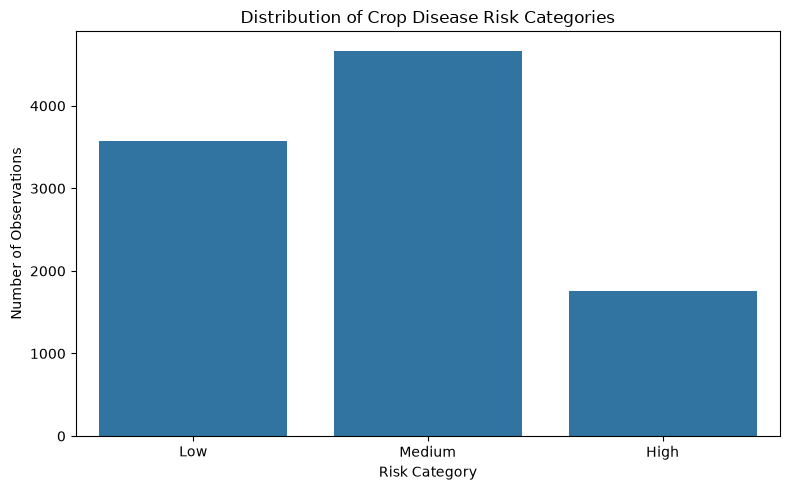

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="risk_label",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Crop Disease Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

NUMERICAL FEATURES

In [10]:
numerical_features = [
    "day_of_year",
    "avg_temp_c",
    "avg_humidity_pct",
    "rainfall_mm",
    "leaf_wetness_hours",
    "wind_speed_kmph",
    "soil_moisture_pct",
    "prior_regional_incidence_pct"
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
day_of_year,10000.0,165.89660,60.827463,60.0,113.0,167.0,219.000,269.0
avg_temp_c,10000.0,21.10825,8.348521,-2.0,15.7,21.5,27.000,45.0
avg_humidity_pct,10000.0,66.71999,18.632616,20.0,53.8,67.4,80.000,100.0
rainfall_mm,10000.0,4.83226,4.862658,0.0,1.3,3.3,6.700,53.2
leaf_wetness_hours,10000.0,4.88631,4.113860,0.0,1.4,4.3,7.425,20.0
wind_speed_kmph,10000.0,10.60626,5.823749,0.0,6.5,10.1,14.100,41.2
soil_moisture_pct,10000.0,48.97972,19.360676,5.0,35.2,48.3,62.300,100.0
prior_regional_incidence_pct,10000.0,17.95957,11.169397,0.0,9.4,17.7,25.700,55.7


NUMERICAL DISTRIBUTIONS

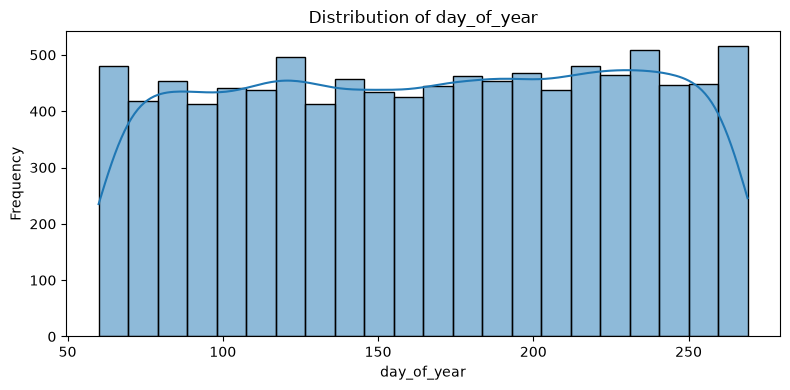

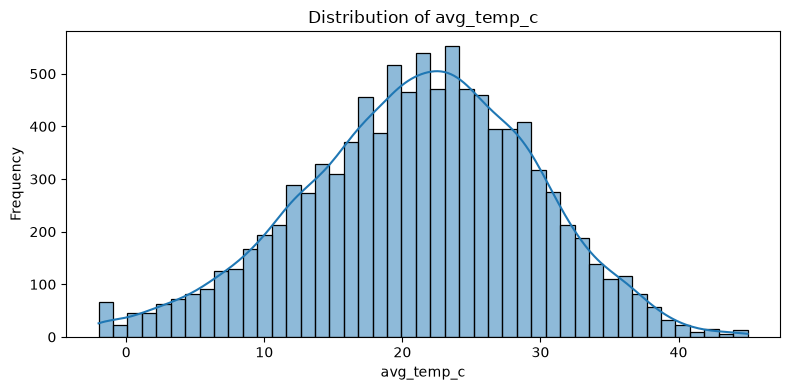

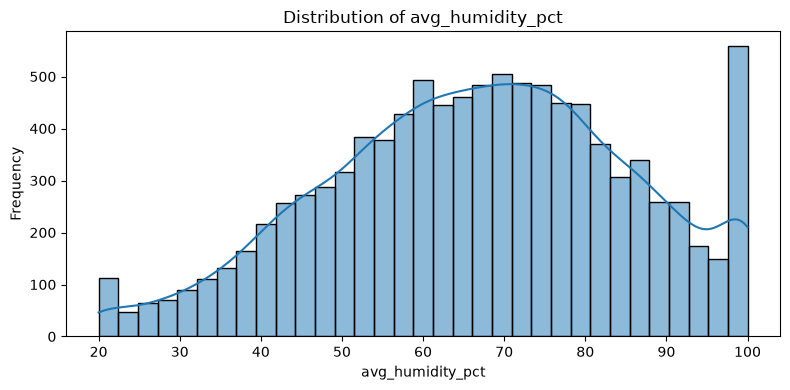

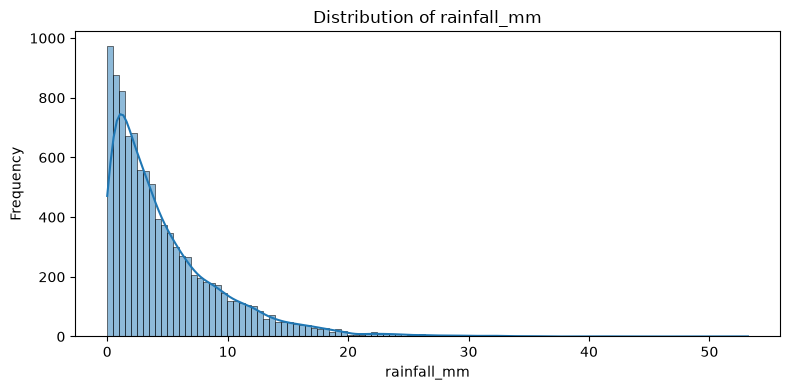

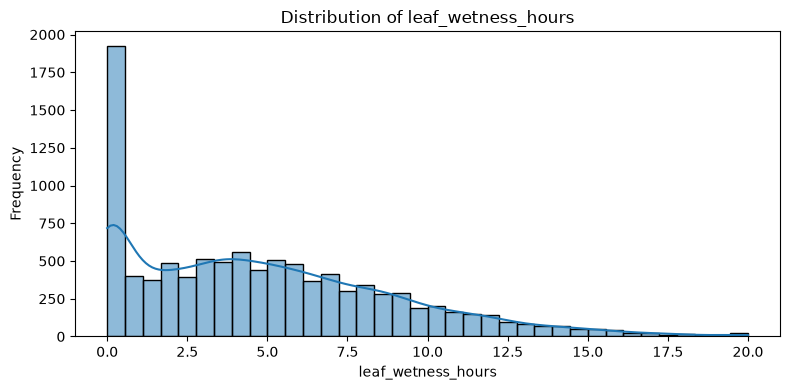

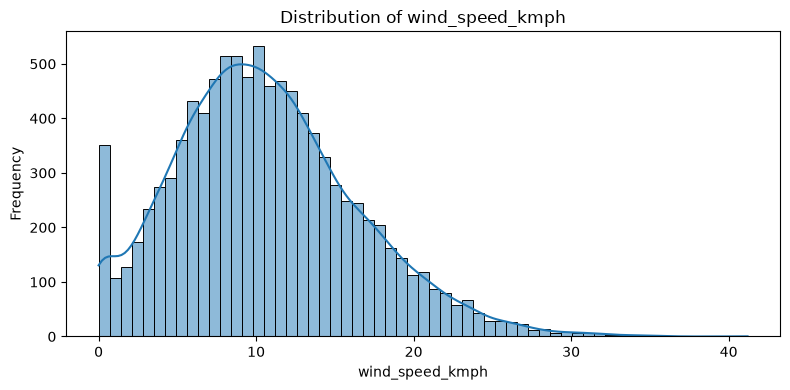

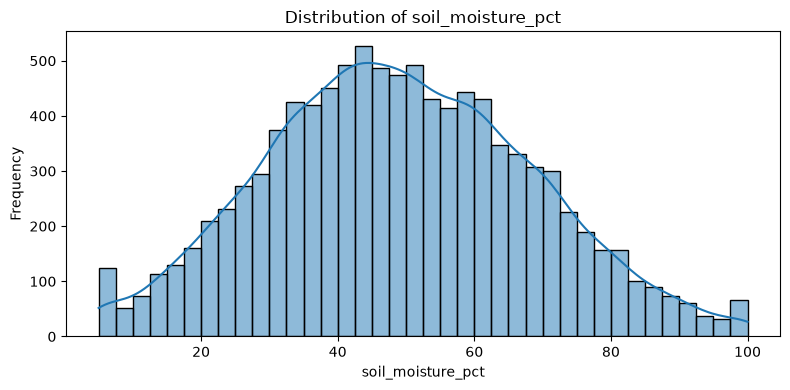

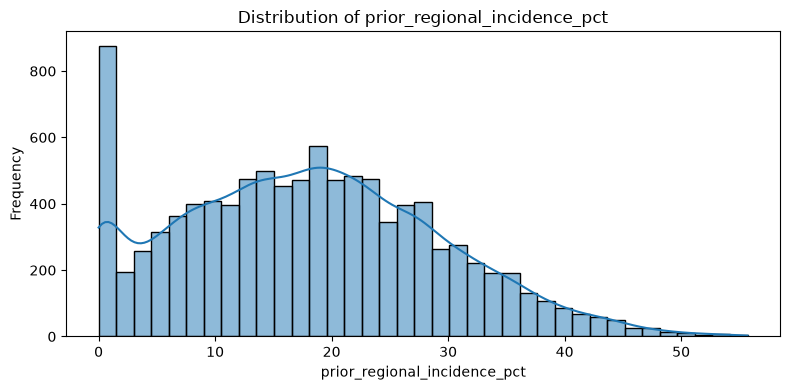

In [11]:
for column in numerical_features:
    
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

CATEGORICAL FEATURES

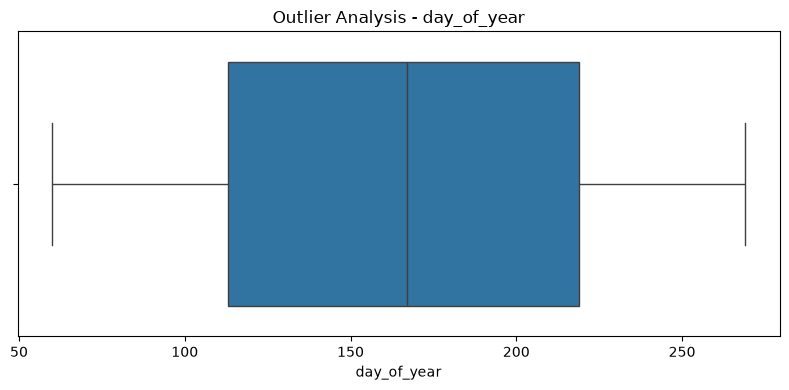

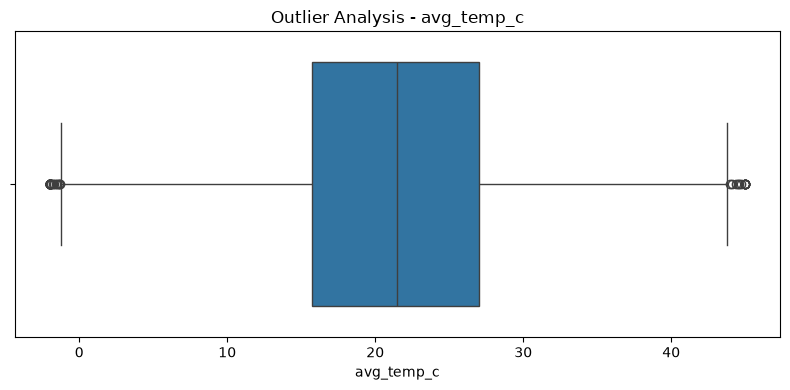

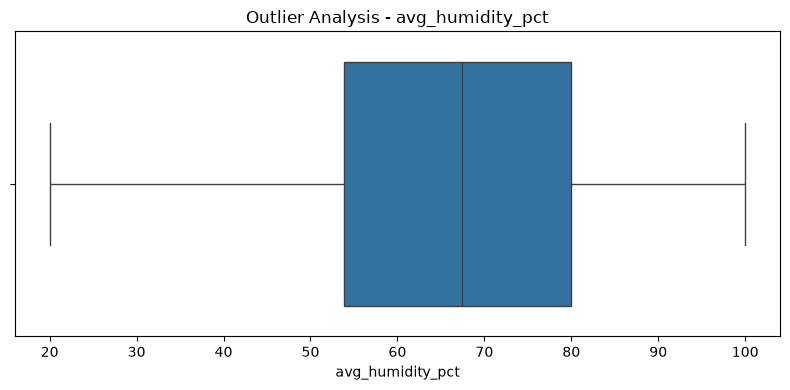

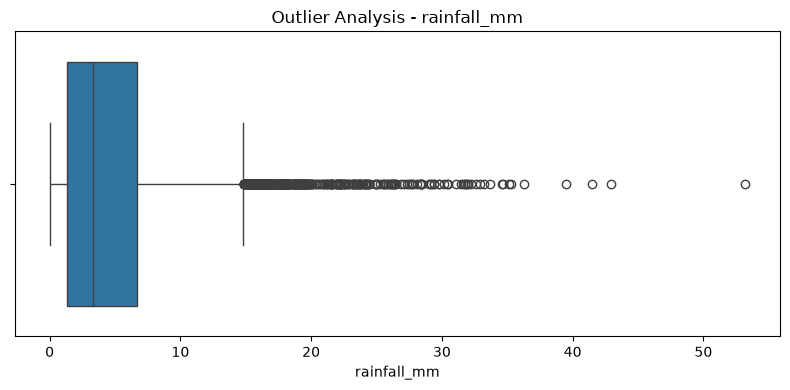

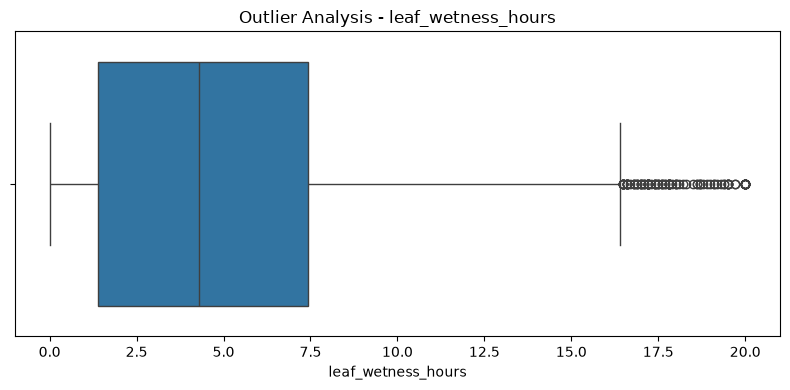

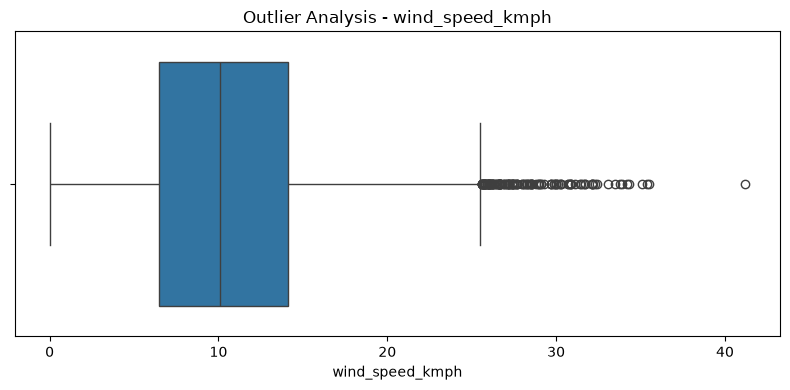

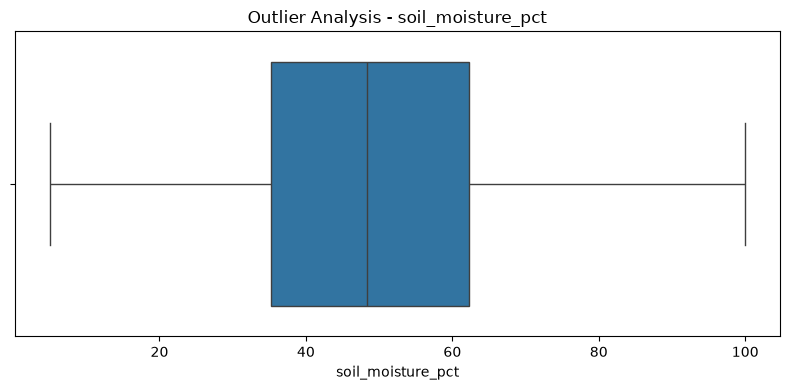

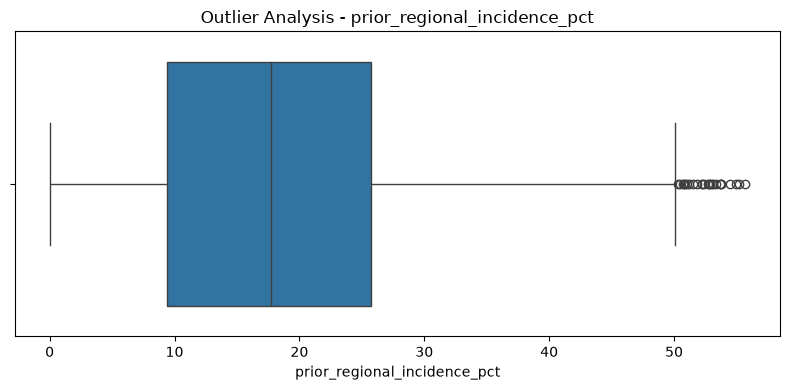

In [12]:
categorical_features = [
    "crop",
    "disease",
    "growth_stage"
]
# Outlier Analysis for Numerical Features

for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=column
    )

    plt.title(f"Outlier Analysis - {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()


RISK VS CROP

In [13]:
crop_risk = pd.crosstab(
    df["crop"],
    df["risk_label"],
    normalize="index"
) * 100

crop_risk

risk_label,High,Low,Medium
crop,,,
Cotton,16.65,25.55,57.80
Grape,29.75,23.10,47.15
Potato,14.60,40.30,45.10
Rice,11.15,48.15,40.70
Wheat,15.70,41.60,42.70


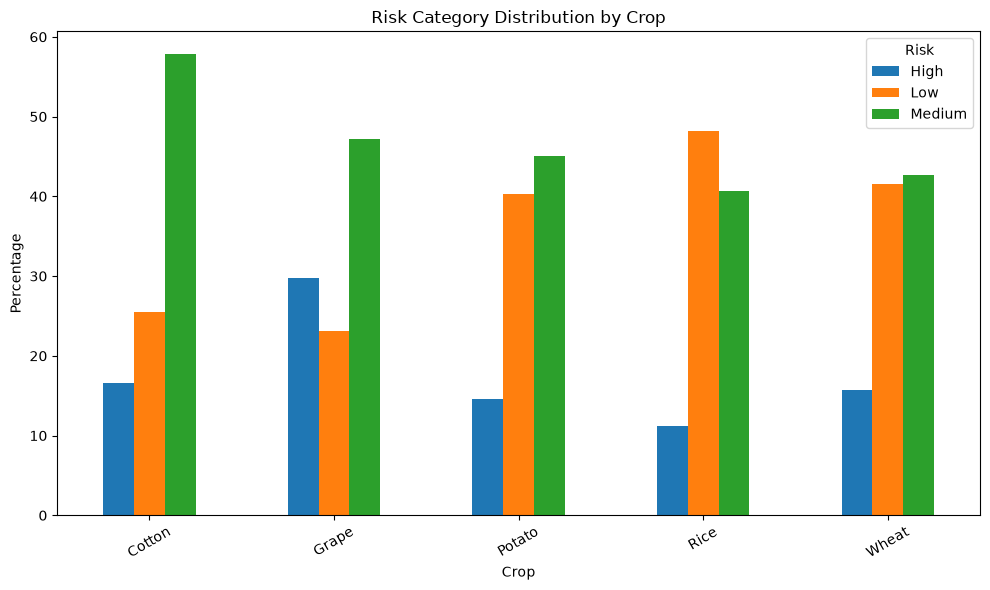

In [14]:
crop_risk.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Risk Category Distribution by Crop")
plt.xlabel("Crop")
plt.ylabel("Percentage")

plt.xticks(rotation=30)
plt.legend(title="Risk")

plt.tight_layout()
plt.show()

RISK VS DISEASE

In [15]:
disease_risk = pd.crosstab(
    df["disease"],
    df["risk_label"],
    normalize="index"
) * 100

disease_risk

risk_label,High,Low,Medium
disease,,,
Bacterial Blight,16.65,25.55,57.80
Blast,11.15,48.15,40.70
Late Blight,14.60,40.30,45.10
Powdery Mildew,29.75,23.10,47.15
Stripe Rust,15.70,41.60,42.70


CORRELATION

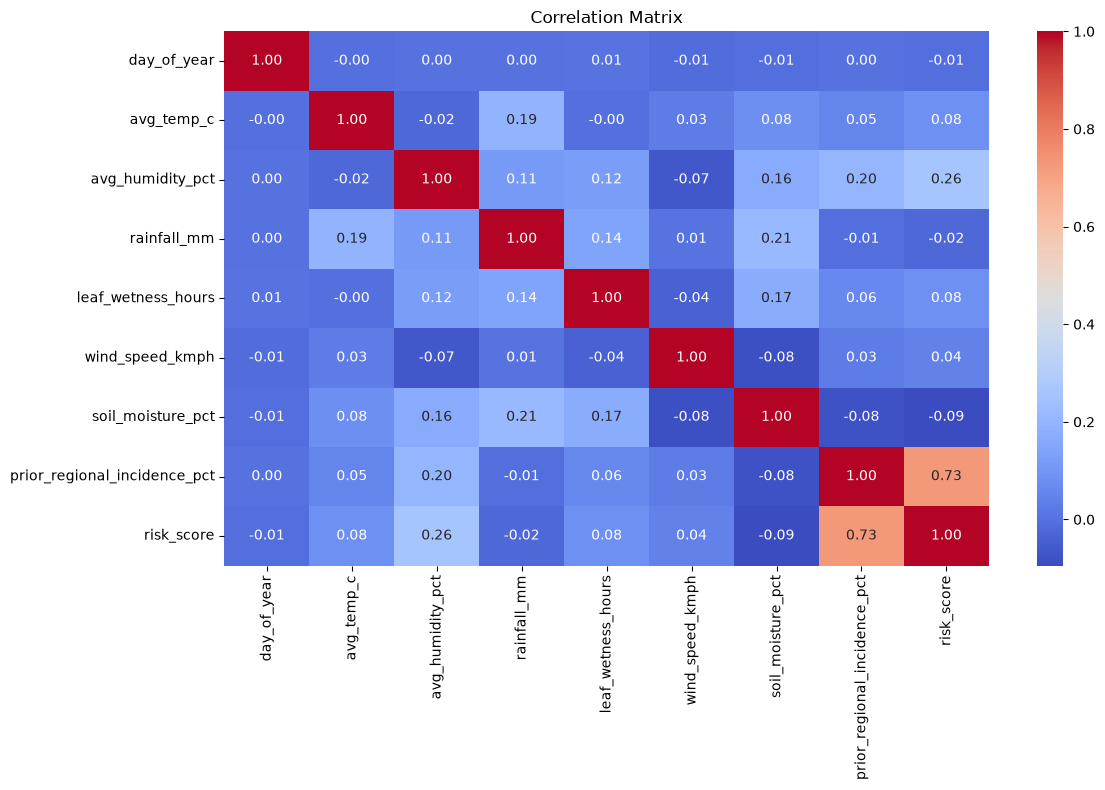

In [16]:
correlation_features = [
    "day_of_year",
    "avg_temp_c",
    "avg_humidity_pct",
    "rainfall_mm",
    "leaf_wetness_hours",
    "wind_speed_kmph",
    "soil_moisture_pct",
    "prior_regional_incidence_pct",
    "risk_score"
]

plt.figure(figsize=(12, 8))

correlation_matrix = df[correlation_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

OUTLIER ANALYSIS

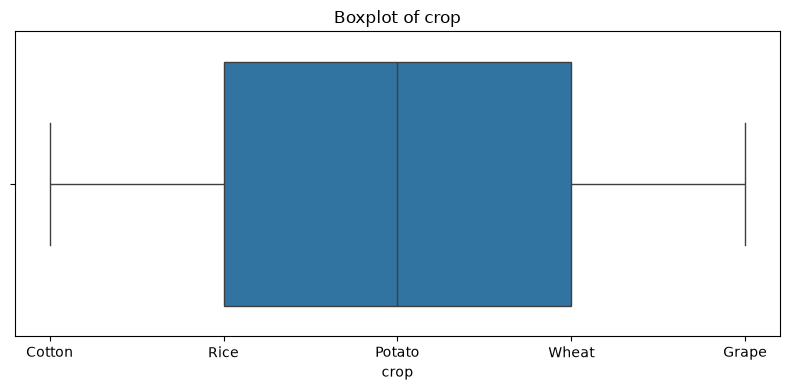

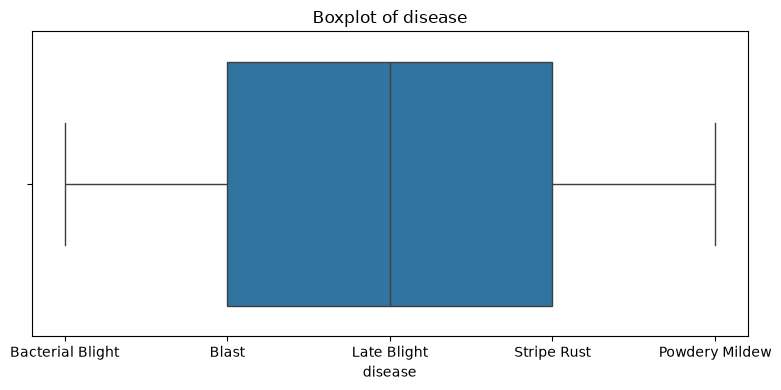

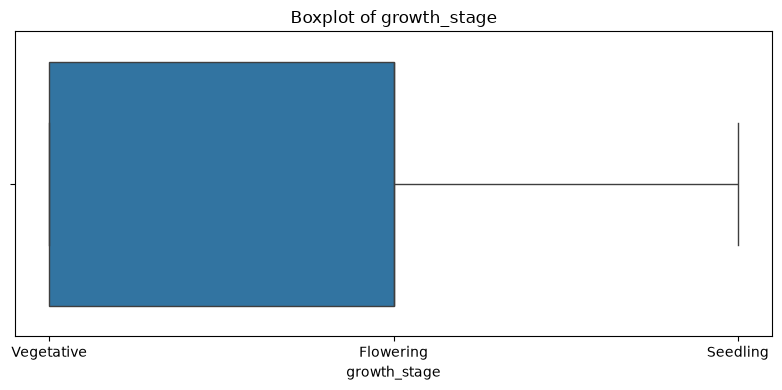

In [17]:
for column in categorical_features:
    
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=column
    )

    plt.title(f"Boxplot of {column}")

    plt.tight_layout()
    plt.show()

MODEL DATA PREPARATION

In [18]:
from sklearn.model_selection import train_test_split

TARGET = "risk_label"

DROP_COLUMNS = [
    TARGET,
    "risk_score"
]

X = df.drop(columns=DROP_COLUMNS)

y = df[TARGET]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Feature shape: (10000, 11)
Target shape: (10000,)

Features:
['crop', 'disease', 'day_of_year', 'avg_temp_c', 'avg_humidity_pct', 'rainfall_mm', 'leaf_wetness_hours', 'wind_speed_kmph', 'soil_moisture_pct', 'prior_regional_incidence_pct', 'growth_stage']

Target classes:
<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


TRAIN TEST SPLIT

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


PREPROCESSING PIPELINE

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_features = [
    "crop",
    "disease",
    "growth_stage"
]

numerical_features = [
    "day_of_year",
    "avg_temp_c",
    "avg_humidity_pct",
    "rainfall_mm",
    "leaf_wetness_hours",
    "wind_speed_kmph",
    "soil_moisture_pct",
    "prior_regional_incidence_pct"
]

In [21]:
#Numerical pipeline

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


In [22]:
#categorical piprline

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [23]:
#combine

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

THREE FOUNDATION MODELS

In [24]:
#Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)


In [25]:
#Decision Tree

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=6,
                random_state=42
            )
        )
    ]
)

In [26]:
#KNN

from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=7
            )
        )
    ]
)

 TRAIN MODELS

In [27]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "KNN": knn_model
}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(
        X_train,
        y_train
    )

    print(f"{name} training completed.")


Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training KNN...
KNN training completed.


 EVALUATION

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
2,KNN,0.6915,0.690940,0.673527,0.681029
1,Decision Tree,0.6725,0.676736,0.653987,0.663108
0,Logistic Regression,0.6860,0.696199,0.641522,0.659921


 CLASSIFICATION REPORT

In [29]:
for name, model in models.items():
    
    print("\n")
    print("=" * 70)
    print(name)
    print("=" * 70)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )



Logistic Regression
              precision    recall  f1-score   support

        High     0.6833    0.4672    0.5550       351
         Low     0.7657    0.6993    0.7310       715
      Medium     0.6396    0.7580    0.6938       934

    accuracy                         0.6860      2000
   macro avg     0.6962    0.6415    0.6599      2000
weighted avg     0.6923    0.6860    0.6827      2000



Decision Tree
              precision    recall  f1-score   support

        High     0.6469    0.5897    0.6170       351
         Low     0.7480    0.6559    0.6990       715
      Medium     0.6353    0.7163    0.6734       934

    accuracy                         0.6725      2000
   macro avg     0.6767    0.6540    0.6631      2000
weighted avg     0.6776    0.6725    0.6726      2000



KNN
              precision    recall  f1-score   support

        High     0.6512    0.6011    0.6252       351
         Low     0.7641    0.7021    0.7318       715
      Medium     0.6575    0.71

CONFUSION MATRIX

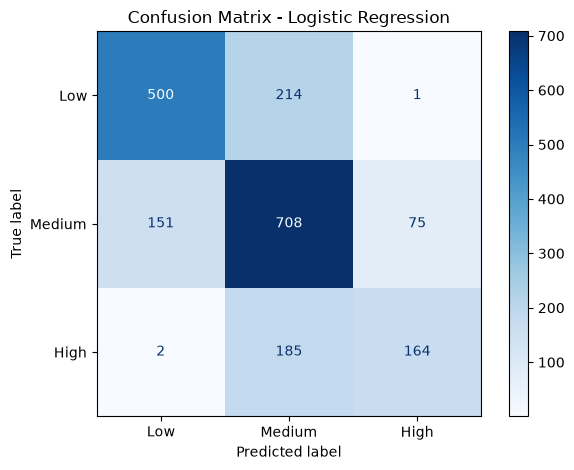

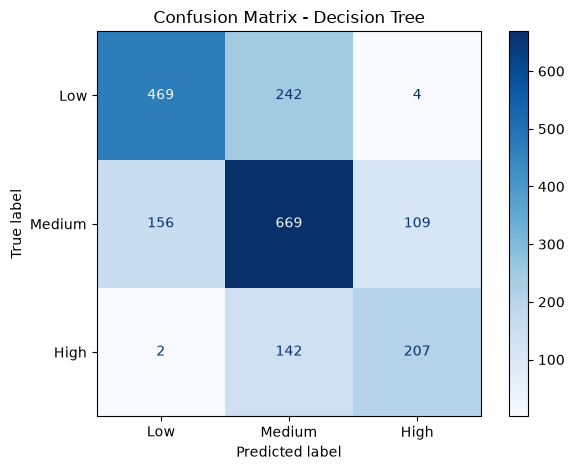

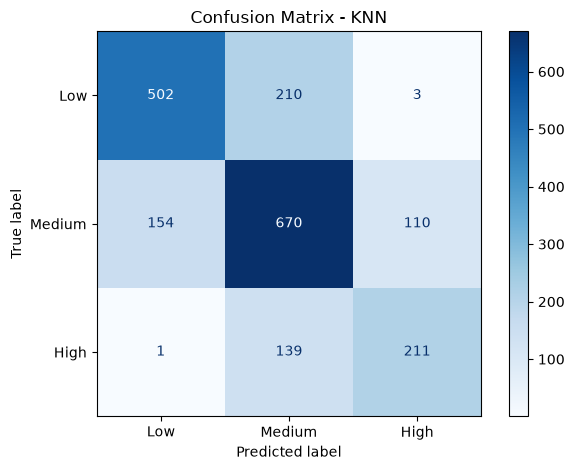

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        cmap="Blues"
    )

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.tight_layout()
    plt.show()

In [31]:
# Error Analysis for the selected KNN model

from sklearn.metrics import confusion_matrix
import pandas as pd

# Generate predictions
y_pred_knn = knn_model.predict(X_test)

# Create error analysis dataframe
error_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_knn
})

# Show only misclassified observations
misclassified = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Total test samples:", len(error_analysis))
print("Correct predictions:", (error_analysis["Actual"] == error_analysis["Predicted"]).sum())
print("Incorrect predictions:", len(misclassified))

print("\nMisclassification summary:")
print(
    pd.crosstab(
        error_analysis["Actual"],
        error_analysis["Predicted"]
    )
)

print("\nSample misclassified observations:")
display(misclassified.head(20))

Total test samples: 2000
Correct predictions: 1383
Incorrect predictions: 617

Misclassification summary:
Predicted  High  Low  Medium
Actual                      
High        211    1     139
Low           3  502     210
Medium      110  154     670

Sample misclassified observations:


,Actual,Predicted
1,Low,Medium
2,High,Medium
3,High,Medium
4,Low,Medium
5,Low,Medium
6,Low,Medium
12,Low,Medium
13,High,Medium
16,High,Medium
19,High,Medium


BEST MODEL SELECTION

In [32]:

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("MODEL COMPARISON")
print("=" * 70)

display(results_df)

best_model_name = results_df.loc[0, "Model"]

print("\nBest model based on Macro F1-score:")
print(best_model_name)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.6915,0.690940,0.673527,0.681029
1,Decision Tree,0.6725,0.676736,0.653987,0.663108
2,Logistic Regression,0.6860,0.696199,0.641522,0.659921



Best model based on Macro F1-score:
KNN


FINAL MODEL EVALUATION

In [33]:

best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("=" * 70)
print(f"FINAL MODEL: {best_model_name}")
print("=" * 70)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_best,
        labels=["Low", "Medium", "High"],
        digits=4,
        zero_division=0
    )
)

FINAL MODEL: KNN

Classification Report:

              precision    recall  f1-score   support

         Low     0.7641    0.7021    0.7318       715
      Medium     0.6575    0.7173    0.6861       934
        High     0.6512    0.6011    0.6252       351

    accuracy                         0.6915      2000
   macro avg     0.6909    0.6735    0.6810      2000
weighted avg     0.6945    0.6915    0.6918      2000



FINAL CONFUSION MATRIX

<Figure size 700x600 with 0 Axes>

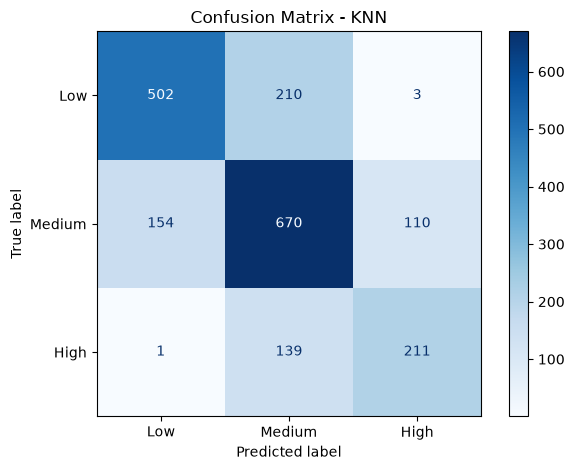

In [34]:

from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=["Low", "Medium", "High"],
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.tight_layout()
plt.show()

FINAL METRICS TABLE

In [35]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

final_accuracy = accuracy_score(
    y_test,
    y_pred_best
)

final_precision = precision_score(
    y_test,
    y_pred_best,
    average="macro",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_pred_best,
    average="macro",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_pred_best,
    average="macro",
    zero_division=0
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1 Score"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

final_metrics["Score"] = final_metrics["Score"].round(4)

display(final_metrics)

,Metric,Score
0,Accuracy,0.6915
1,Macro Precision,0.6909
2,Macro Recall,0.6735
3,Macro F1 Score,0.6810


TRAIN FINAL DEPLOYMENT MODEL

In [36]:

final_model = models[best_model_name]

final_model.fit(
    X,
    y
)

print("Final deployment model trained successfully.")
print("Model:", best_model_name)
print("Training samples:", len(X))

Final deployment model trained successfully.
Model: KNN
Training samples: 10000


SAVE FINAL MODEL

In [37]:

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = MODEL_DIR / "crop_disease_model.pkl"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("Model saved successfully.")
print("Location:", MODEL_PATH)

Model saved successfully.
Location: ..\models\crop_disease_model.pkl


In [38]:
# ============================================================
# LOAD SAVED MODEL
# ============================================================

loaded_model = joblib.load(
    MODEL_PATH
)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [39]:
# ============================================================
# SAMPLE PREDICTION
# ============================================================

sample_input = pd.DataFrame({
    "crop": ["Rice"],
    "disease": ["Blast"],
    "growth_stage": ["Vegetative"],
    "day_of_year": [180],
    "avg_temp_c": [28.0],
    "avg_humidity_pct": [82.0],
    "rainfall_mm": [120.0],
    "leaf_wetness_hours": [10.0],
    "wind_speed_kmph": [8.0],
    "soil_moisture_pct": [65.0],
    "prior_regional_incidence_pct": [40.0]
})

prediction = loaded_model.predict(
    sample_input
)[0]

print("Predicted Disease Risk:", prediction)

Predicted Disease Risk: Medium


In [40]:
# ============================================================
# PREDICTION PROBABILITY
# ============================================================

prediction_probabilities = loaded_model.predict_proba(
    sample_input
)[0]

class_names = loaded_model.classes_

probability_df = pd.DataFrame({
    "Risk Category": class_names,
    "Probability": prediction_probabilities
})

probability_df["Probability (%)"] = (
    probability_df["Probability"] * 100
).round(2)

display(
    probability_df[
        ["Risk Category", "Probability (%)"]
    ]
)

print("Predicted Risk:", prediction)

,Risk Category,Probability (%)
0,High,28.57
1,Low,28.57
2,Medium,42.86


Predicted Risk: Medium


In [41]:
# ============================================================
# FINAL MODEL CHECK
# ============================================================

print("Project Model Information")
print("=" * 50)

print("Selected Model:", best_model_name)
print("Model File:", MODEL_PATH)
print("Number of Training Rows:", len(X))
print("Number of Original Features:", X.shape[1])

print("\nFeatures used by model:")
for feature in X.columns:
    print("-", feature)

print("\nExcluded from model:")
print("- risk_label  → target")
print("- risk_score  → excluded to avoid target leakage")

Project Model Information
Selected Model: KNN
Model File: ..\models\crop_disease_model.pkl
Number of Training Rows: 10000
Number of Original Features: 11

Features used by model:
- crop
- disease
- day_of_year
- avg_temp_c
- avg_humidity_pct
- rainfall_mm
- leaf_wetness_hours
- wind_speed_kmph
- soil_moisture_pct
- prior_regional_incidence_pct
- growth_stage

Excluded from model:
- risk_label  → target
- risk_score  → excluded to avoid target leakage
